# Stage 2 alternatives: one different idea at a time on Resa's model (MASSIVE 1.0 en-US)

**Owner:** Nicholas. **Purpose:** the "one thing different from Resa's and Yuxuan's BiLSTM" requested in the group
chat, chosen by experiment rather than up front. Companion to `m4_nicholas.ipynb` (same pipeline, same seeds, same
keep rule), so its cached results for the reference and Stack-Propagation are reused.

**AI collaboration:** written together with Claude (Anthropic, Claude Opus 5.5) as part of the Stage 2 AI
collaboration; the chat goes into `ai_collaboration.md`.

**Ideas tested** (each one change on top of Resa's Stage 2 model, chosen from the measured weaknesses):
Stack-Propagation (word-level intent voting), **A** BIOES tagging (span boundaries), **B** hierarchical
scenario → intent prediction (cross-scenario intent errors), **C** intent-slot compatibility decoding (slot types
that do not fit the request). The best one is then combined with the regularisers (label smoothing + count-based
word dropout) and confirmed with 5 seeds.

| Section | Content |
|---|---|
| 0-4 | Setup, data checks, text processing and shared evaluation, vocabulary and embeddings, CRF and char-CNN (unchanged shared pipeline, plus BIOES / scenario / compatibility maps) |
| 5 | Models and unit checks for the new parts |
| 6 | Training and evaluation utilities (unchanged) |
| 7 | Validation experiments, 3 seeds, then 5-seed confirmation of the finalists |
| 8 | Official run of the selected configuration, reload, single test evaluation |
| 9 | Error comparison: best single change vs the reference |

## 0. Setup and configuration

In [1]:
import json
import math
import os
import platform
import random
import re
import shutil
import tarfile
import time
import urllib.request
import zipfile
import itertools
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seqeval.metrics
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader

try:
    from IPython.display import display
except ImportError:          # plain python: print instead
    display = print

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


print(f"python      {platform.python_version()}")
print(f"torch       {torch.__version__}")
print(f"device      {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

python      3.12.0
torch       2.11.0+cu128
device      cuda (NVIDIA GeForce RTX 4070 Laptop GPU)


In [2]:
# ---- Paths (runs/ and data/ are git-ignored) ----
DATA_DIR = Path("data")
OUT_DIR = Path("runs") / "alt"
CKPT_DIR, FIG_DIR = OUT_DIR / "checkpoints", OUT_DIR / "figures"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

MASSIVE_URL = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz"
MASSIVE_TAR = DATA_DIR / "amazon-massive-dataset-1.0.tar.gz"
MASSIVE_JSONL = DATA_DIR / "en-US.jsonl"
GLOVE_URLS = ["https://nlp.stanford.edu/data/glove.6B.zip",
              "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"]
GLOVE_ZIP, GLOVE_TXT = DATA_DIR / "glove.6B.zip", DATA_DIR / "glove.6B.300d.txt"
EMB_DIM = 300

EXPECTED_SPLITS = {"train": 11_514, "dev": 2_033, "test": 2_974}
PARAM_CAP = 20_000_000

# ---- Training recipe: identical to the team's Stage 2 (full_version_resa.ipynb) ----
BASE_CFG = dict(
    hidden=256, layers=2, dropout=0.3, word_dropout=0.1, wd_alpha=0.0,
    lr=1e-3, weight_decay=1e-2, batch_size=32, grad_clip=5.0, lr_schedule="plateau",
    char_cnn=True, crf=True, slot_loss_weight=1.0, label_smoothing=0.0,
    interaction="none",                                   # the reference BiLSTM-CRF
    label_att=True, coint_layers=1, d_model=256, heads=4, ffn_mult=2,   # used by interaction="coint"
)
MAX_EPOCHS = 60
PATIENCE = 8                 # early stopping on the validation selection score
EVAL_BATCH_SIZE = 256
SEEDS = [42, 43, 44]         # same seeds as the team's Stage 2 development runs
OFFICIAL_SEED = 42

# QUICK=1 only checks that every cell runs (tiny training budget, 1 seed). Results are meaningless in that mode.
QUICK = os.environ.get("M4_QUICK", "0") == "1"
if QUICK:
    MAX_EPOCHS, SEEDS = 2, [42]
    print("QUICK MODE: smoke test only, numbers are not results")

## 1. Load and verify the dataset

MASSIVE 1.0, file `1.0/data/en-US.jsonl`, split by the existing `partition` field. Nothing is added, removed or moved.

In [3]:
def download(url, dest):
    dest = Path(dest)
    if dest.exists():
        return dest
    tmp = dest.with_name(dest.name + ".part")
    print(f"downloading {url}")
    with urllib.request.urlopen(url, timeout=60) as response, open(tmp, "wb") as f:
        shutil.copyfileobj(response, f, length=1 << 20)
    tmp.rename(dest)
    return dest


if not MASSIVE_JSONL.exists():
    download(MASSIVE_URL, MASSIVE_TAR)
    with tarfile.open(MASSIVE_TAR, "r:gz") as tar:
        member = next(m for m in tar.getmembers() if m.name.endswith("1.0/data/en-US.jsonl"))
        with tar.extractfile(member) as src, open(MASSIVE_JSONL, "wb") as dst:
            shutil.copyfileobj(src, dst)

with open(MASSIVE_JSONL, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]
splits = {name: [r for r in records if r["partition"] == name] for name in EXPECTED_SPLITS}
for name, expected in EXPECTED_SPLITS.items():
    print(f"{name:5s}: {len(splits[name]):,} examples")
    assert len(splits[name]) == expected
assert sum(len(v) for v in splits.values()) == 16_521
assert all(r["locale"] == "en-US" for r in records)
print("split sizes verified: 11,514 / 2,033 / 2,974")

train: 11,514 examples
dev  : 2,033 examples
test : 2,974 examples
split sizes verified: 11,514 / 2,033 / 2,974


## 2. Text processing and shared evaluation functions

Unchanged from the shared pipeline. Gold slots are parsed from `annot_utt` and aligned to `utt` by character
offsets; tokens use the Penn-Treebank-style split (`today's` → `today` `'s`) that the team chose because it is the
only tokenizer whose decoded gold tags reproduce 100% of the gold slots. Slot micro F1 is computed on
`(slot type, span text)` pairs, pooled over all utterances.

In [4]:
SLOT_RE = re.compile(r"\[(\S+) : ([^\]]+)\]")
TOKEN_RE = re.compile(r"\w+(?=n't\b)|n't\b|'\w+|\w+|[^\w\s]")
TOKENIZER = "ptb_split"


def norm_ws(s):
    return " ".join(s.split())


def parse_annot(utt, annot):
    """Gold slots as [(type, span_text, char_start, char_end)], with offsets into utt."""
    slots, i, pos = [], 0, 0

    def skip_space(i):
        while i < len(utt) and utt[i].isspace():
            i += 1
        return i

    def consume(segment, i):
        for ch in segment:
            if ch.isspace():
                continue
            i = skip_space(i)
            if i >= len(utt) or utt[i].lower() != ch.lower():
                raise ValueError(f"annot_utt does not match utt: {utt!r} / {annot!r}")
            i += 1
        return i

    for m in SLOT_RE.finditer(annot):
        i = consume(annot[pos:m.start()], i)
        start = skip_space(i)
        i = consume(m.group(2), start)
        slots.append((m.group(1), norm_ws(utt[start:i]), start, i))
        pos = m.end()
    i = consume(annot[pos:], i)
    assert not utt[i:].strip()
    return slots


def tokenize(text):
    return [(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def bio_tags(tokens, slots):
    tags = ["O"] * len(tokens)
    for stype, _, s, e in slots:
        first = True
        for k, (_, ts, te) in enumerate(tokens):
            if ts < e and te > s and tags[k] == "O":
                tags[k] = ("B-" if first else "I-") + stype
                first = False
    return tags


def tags_to_spans(tags):
    """BIO tags -> [(type, first_token, last_token)]; a stray I-X starts a new span (CoNLL rule)."""
    spans, k = [], 0
    while k < len(tags):
        if tags[k] == "O":
            k += 1
            continue
        stype, start = tags[k][2:], k
        k += 1
        while k < len(tags) and tags[k] == "I-" + stype:
            k += 1
        spans.append((stype, start, k - 1))
    return spans


def spans_to_pairs(spans, tokens, utt):
    return Counter((stype, norm_ws(utt[tokens[a][1]:tokens[b][2]])) for stype, a, b in spans)


def intent_accuracy(gold, pred):
    assert len(gold) == len(pred) and len(gold) > 0
    return 100.0 * sum(g == p for g, p in zip(gold, pred)) / len(gold)


def slot_micro_prf(gold_pairs, pred_pairs):
    tp = fp = fn = 0
    for g, p in zip(gold_pairs, pred_pairs):
        hit = sum((g & p).values())
        tp += hit
        fp += sum(p.values()) - hit
        fn += sum(g.values()) - hit
    denom = 2 * tp + fp + fn
    return dict(f1=100.0 * 2 * tp / denom if denom else 100.0,
                precision=100.0 * tp / (tp + fp) if tp + fp else 0.0,
                recall=100.0 * tp / (tp + fn) if tp + fn else 0.0, tp=tp, fp=fp, fn=fn)


def selection_score(intent_acc, slot_f1):
    """Checkpoint and model selection score (team choice): mean of intent accuracy and slot micro F1."""
    return (intent_acc + slot_f1) / 2


def score_predictions(examples, pred_intents, pred_tags):
    gold_int = [ex["intent"] for ex in examples]
    gold_pairs = [ex["gold_pairs"] for ex in examples]
    pred_pairs = [spans_to_pairs(tags_to_spans(t), ex["tokens"], ex["utt"]) for ex, t in zip(examples, pred_tags)]
    acc = intent_accuracy(gold_int, pred_intents)
    prf = slot_micro_prf(gold_pairs, pred_pairs)
    em = 100.0 * sum(gi == pi and gp == pp for gi, pi, gp, pp
                     in zip(gold_int, pred_intents, gold_pairs, pred_pairs)) / len(examples)
    return dict(intent_acc=acc, slot_f1=prf["f1"], slot_precision=prf["precision"], slot_recall=prf["recall"],
                exact_match=em, score=selection_score(acc, prf["f1"]))


# ---- Unit tests (same cases as the shared notebook) ----
def _pred(utt, tags):
    toks = tokenize(utt)
    return spans_to_pairs(tags_to_spans(tags), toks, utt)


def _f1(gold, pred):
    return round(slot_micro_prf(gold, pred)["f1"], 4)


_U = "wake me up at five am this week"
_G = Counter({("time", "five am"): 1, ("date", "this week"): 1})
assert _f1([_G], [_pred(_U, "O O O O B-time I-time B-date I-date".split())]) == 100.0
assert _f1([_G], [_pred(_U, "O O O O B-time O B-date I-date".split())]) == 50.0       # boundary error
assert _f1([_G], [_pred(_U, "O O O O B-date I-date B-date I-date".split())]) == 50.0  # type error
assert _f1([_G], [_pred(_U, "O O O O B-time I-time O O".split())]) == round(100 * 2 / 3, 4)
assert _f1([_G], [_pred(_U, "B-person O O O B-time I-time B-date I-date".split())]) == 80.0
assert _f1([Counter()], [Counter()]) == 100.0
_S3 = parse_annot("what is on today's schedule", "what is on [date : today]'s schedule")
assert _S3 == [("date", "today", 11, 16)]
_gt = [["O", "O", "O", "O", "B-time", "I-time", "B-date", "I-date"]]
_pt = [["O", "O", "O", "O", "B-time", "O", "B-date", "I-date"]]
assert round(100 * seqeval.metrics.f1_score(_gt, _pt), 4) == _f1([_G], [_pred(_U, _pt[0])])
print("evaluation unit tests passed")

evaluation unit tests passed


## 3. Vocabulary, labels, GloVe embedding matrix, characters

Everything is built from the **training split only**. Words outside the training vocabulary become `<unk>` at test
time. GloVe 6B 300d rows are kept only for training words (1.54M parameters, counted in the total).

In [5]:
PAD, UNK, IGNORE = 0, 1, -100


def build_examples(split_records):
    out = []
    for r in split_records:
        slots = parse_annot(r["utt"], r["annot_utt"])
        toks = tokenize(r["utt"])
        out.append(dict(id=r["id"], utt=r["utt"], intent=r["intent"], scenario=r["scenario"], tokens=toks,
                        words=[t[0].lower() for t in toks], tags=bio_tags(toks, slots),
                        gold_pairs=Counter((s[0], s[1]) for s in slots)))
    return out


EXAMPLES = {name: build_examples(recs) for name, recs in splits.items()}
_missed = sum(spans_to_pairs(tags_to_spans(ex["tags"]), ex["tokens"], ex["utt"]) != ex["gold_pairs"]
              for ex in EXAMPLES["train"])
assert _missed == 0, "tokenizer cannot represent some gold slots"

word_counts = Counter(w for ex in EXAMPLES["train"] for w in ex["words"])
ITOS = ["<pad>", "<unk>"] + [w for w, _ in word_counts.most_common()]
STOI = {w: i for i, w in enumerate(ITOS)}
V = len(ITOS)
ID2INTENT = sorted({ex["intent"] for ex in EXAMPLES["train"]})
INTENT2ID = {x: i for i, x in enumerate(ID2INTENT)}
SLOT_TYPES = sorted({t[2:] for ex in EXAMPLES["train"] for t in ex["tags"] if t != "O"})
ID2TAG = ["O"] + [f"{p}-{s}" for s in SLOT_TYPES for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(ID2TAG)}
N_INTENTS, N_TAGS = len(ID2INTENT), len(ID2TAG)
print(f"vocabulary V = {V:,}; intents = {N_INTENTS}; slot types = {len(SLOT_TYPES)}; BIO tags = {N_TAGS}")
assert (N_INTENTS, len(SLOT_TYPES)) == (60, 55)

# ---- Characters (training words only) ----
MAX_WORD_LEN = 20
CHAR_ITOS = ["<pad>", "<unk>"] + sorted({ch for ex in EXAMPLES["train"] for w in ex["words"] for ch in w})
CHAR2ID = {c: i for i, c in enumerate(CHAR_ITOS)}
N_CHARS = len(CHAR_ITOS)

# count of each vocabulary word in train (for count-based word dropout, an option from full_version_evan.ipynb)
WORD_COUNT = torch.tensor([0, 0] + [word_counts[w] for w in ITOS[2:]], dtype=torch.float)


# ---- BIOES tag scheme (variant A): E- marks the last word of a span, S- a one-word span ----
ID2TAG_BIOES = ["O"] + [f"{p}-{s}" for s in SLOT_TYPES for p in ("B", "I", "E", "S")]
TAG2ID_BIOES = {t: i for i, t in enumerate(ID2TAG_BIOES)}


def bio_to_bioes(tags):
    out = ["O"] * len(tags)
    for stype, a, b in tags_to_spans(tags):
        if a == b:
            out[a] = f"S-{stype}"
        else:
            out[a], out[b] = f"B-{stype}", f"E-{stype}"
            for k in range(a + 1, b):
                out[k] = f"I-{stype}"
    return out


def bioes_to_bio(tags):
    return [("B-" + t[2:]) if t.startswith("S-") else ("I-" + t[2:]) if t.startswith("E-") else t for t in tags]


assert all(bioes_to_bio(bio_to_bioes(ex["tags"])) == ex["tags"] for exs in EXAMPLES.values() for ex in exs), \
    "BIO -> BIOES -> BIO round trip failed"

# ---- Scenarios (variant B): the scenario is the intent's prefix (alarm_set -> alarm); derived from the label ----
ID2SCEN = sorted({i.split("_")[0] for i in ID2INTENT})
INTENT2SCEN = torch.tensor([ID2SCEN.index(i.split("_")[0]) for i in ID2INTENT])
N_SCEN = len(ID2SCEN)

# ---- Intent-slot compatibility (variant C): slot types seen with each intent in the training split ----
COMPAT = torch.zeros(N_INTENTS, len(SLOT_TYPES), dtype=torch.bool)
for ex in EXAMPLES["train"]:
    for (stype, _) in ex["gold_pairs"]:
        COMPAT[INTENT2ID[ex["intent"]], SLOT_TYPES.index(stype)] = True
_unseen = sum(stype not in {SLOT_TYPES[j] for j in COMPAT[INTENT2ID[ex["intent"]]].nonzero().flatten().tolist()}
              for ex in EXAMPLES["dev"] for (stype, _) in ex["gold_pairs"].elements())
print(f"scenarios = {N_SCEN}; slot types allowed per intent: mean {COMPAT.sum(1).float().mean():.1f} of {len(SLOT_TYPES)}; "
      f"dev gold slots whose type never occurs with their intent in train: {_unseen}")


def encode(ex):
    return dict(ids=[STOI.get(w, UNK) for w in ex["words"]],
                tag_ids=[TAG2ID.get(t, IGNORE) for t in ex["tags"]],
                tag_ids_bioes=[TAG2ID_BIOES.get(t, IGNORE) for t in bio_to_bioes(ex["tags"])],
                intent_id=INTENT2ID.get(ex["intent"], IGNORE),
                char_ids=[[CHAR2ID.get(c, 1) for c in w[:MAX_WORD_LEN]] for w in ex["words"]])


DATASETS = {name: [(i, encode(ex)) for i, ex in enumerate(exs)] for name, exs in EXAMPLES.items()}
if QUICK:
    DATASETS["train"] = DATASETS["train"][:1500]

vocabulary V = 5,145; intents = 60; slot types = 55; BIO tags = 111
scenarios = 18; slot types allowed per intent: mean 7.2 of 55; dev gold slots whose type never occurs with their intent in train: 16


In [6]:
# GloVe rows for the training vocabulary, cached so later runs skip the 1 GB text file.
_cache = DATA_DIR / f"glove6b300_rows_{V}.npz"
if _cache.exists():
    _z = np.load(_cache, allow_pickle=False)
    assert list(_z["words"]) == ITOS
    EMB_MATRIX, _found = _z["matrix"], _z["found"]
else:
    if not GLOVE_TXT.exists():
        if not GLOVE_ZIP.exists():
            for url in GLOVE_URLS:
                try:
                    download(url, GLOVE_ZIP)
                    break
                except Exception as e:
                    print(f"  failed: {e}")
        with zipfile.ZipFile(GLOVE_ZIP) as z, z.open("glove.6B.300d.txt") as src, open(GLOVE_TXT, "wb") as dst:
            shutil.copyfileobj(src, dst, length=1 << 20)
    vecs = {}
    with open(GLOVE_TXT, encoding="utf-8") as f:
        for line in f:
            w, rest = line.rstrip("\n").split(" ", 1)
            if w in STOI:
                vecs[w] = np.asarray(rest.split(" "), dtype=np.float32)
    std = np.stack(list(vecs.values())).std()
    EMB_MATRIX = np.random.default_rng(0).normal(0.0, std, size=(V, EMB_DIM)).astype(np.float32)
    _found = np.zeros(V, dtype=bool)
    for w, vec in vecs.items():
        EMB_MATRIX[STOI[w]], _found[STOI[w]] = vec, True
    EMB_MATRIX[PAD] = 0.0
    np.savez(_cache, words=np.array(ITOS), matrix=EMB_MATRIX, found=_found)
print(f"training word types found in GloVe: {_found[2:].sum():,} / {V - 2:,}; embedding matrix {EMB_MATRIX.shape}")

training word types found in GloVe: 4,959 / 5,143; embedding matrix (5145, 300)


## 4. Building blocks: CRF and character CNN

Same CRF as the shared notebook: BIO constraints (an `I-X` may only follow `B-X` or `I-X`) are hard-coded as
-1e4 transition scores, so decoding never outputs an invalid tag sequence. The forward algorithm and Viterbi are
checked against brute-force enumeration before any training.

In [7]:
class CRF(nn.Module):
    def __init__(self, n_tags, allowed=None, start_allowed=None):
        super().__init__()
        self.n_tags = n_tags
        self.transitions = nn.Parameter(torch.empty(n_tags, n_tags).uniform_(-0.1, 0.1))
        self.start = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        self.end = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        allowed = torch.ones(n_tags, n_tags) if allowed is None else allowed.float()
        start_allowed = torch.ones(n_tags) if start_allowed is None else start_allowed.float()
        self.register_buffer("trans_penalty", (1 - allowed) * -1e4)
        self.register_buffer("start_penalty", (1 - start_allowed) * -1e4)

    def nll(self, emissions, tags, mask):
        """Negative log-likelihood of the gold tags, averaged over real tokens."""
        B, T, K = emissions.shape
        tags = torch.where(mask & (tags >= 0), tags, torch.zeros_like(tags))
        oh = F.one_hot(tags, K).to(emissions.dtype)
        maskf = mask.to(emissions.dtype)
        trans, start = self.transitions + self.trans_penalty, self.start + self.start_penalty
        gold = ((emissions * oh).sum(-1) * maskf).sum(1) + (oh[:, 0] * start).sum(-1)
        gold = gold + (torch.einsum("btk,kl,btl->bt", oh[:, :-1], trans, oh[:, 1:]) * maskf[:, 1:]).sum(1)
        last = mask.sum(1) - 1
        gold = gold + (oh[torch.arange(B, device=tags.device), last] * self.end).sum(-1)
        alpha = start + emissions[:, 0]
        for t in range(1, T):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + trans.unsqueeze(0), dim=1) + emissions[:, t]
            alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)
        log_z = torch.logsumexp(alpha + self.end, dim=1)
        return (log_z - gold).sum() / maskf.sum()

    @torch.no_grad()
    def viterbi(self, emissions, mask):
        B, T, K = emissions.shape
        trans = self.transitions + self.trans_penalty
        score = self.start + self.start_penalty + emissions[:, 0]
        same = torch.arange(K, device=emissions.device).expand(B, K)
        backpointers = []
        for t in range(1, T):
            best, idx = (score.unsqueeze(2) + trans.unsqueeze(0)).max(dim=1)
            m = mask[:, t].unsqueeze(1)
            score = torch.where(m, best + emissions[:, t], score)
            backpointers.append(torch.where(m, idx, same))
        last = (score + self.end).argmax(1)
        path = [last]
        for idx in reversed(backpointers):
            last = idx.gather(1, last.unsqueeze(1)).squeeze(1)
            path.append(last)
        return torch.stack(path[::-1], dim=1)


def bio_constraints(tag_names):
    K = len(tag_names)
    allowed, start = torch.zeros(K, K), torch.zeros(K)
    for j, tj in enumerate(tag_names):
        start[j] = not tj.startswith("I-")
        for i, ti in enumerate(tag_names):
            allowed[i, j] = (not tj.startswith("I-")) or (ti != "O" and ti[2:] == tj[2:])
    return allowed, start


def count_invalid_bio(tag_seqs):
    bad = 0
    for tags in tag_seqs:
        prev = "O"
        for t in tags:
            if t.startswith("I-") and (prev == "O" or prev[2:] != t[2:]):
                bad += 1
            prev = t
    return bad


def _brute(crf, em, length, gold):
    trans, start = crf.transitions + crf.trans_penalty, crf.start + crf.start_penalty
    scores = {}
    for path in itertools.product(range(crf.n_tags), repeat=length):
        s = start[path[0]] + em[0, path[0]] + crf.end[path[-1]]
        for t in range(1, length):
            s = s + trans[path[t - 1], path[t]] + em[t, path[t]]
        scores[path] = s
    log_z = torch.logsumexp(torch.stack(list(scores.values())), 0)
    return max(scores, key=lambda p: scores[p].item()), (log_z - scores[tuple(gold)]).item()


torch.manual_seed(0)
_names = ["O", "B-a", "I-a", "B-b", "I-b"]
for _constrained in (False, True):
    _crf = CRF(5, *bio_constraints(_names)) if _constrained else CRF(5)
    _em, _mask = torch.randn(2, 4, 5), torch.tensor([[1, 1, 1, 1], [1, 1, 1, 0]], dtype=torch.bool)
    _gold = torch.tensor([[1, 2, 0, 3], [3, 4, 0, -100]])
    _vit, _tot = _crf.viterbi(_em, _mask), 0.0
    for b, n in enumerate([4, 3]):
        _best, _nll = _brute(_crf, _em[b], n, _gold[b, :n].tolist())
        assert tuple(_vit[b, :n].tolist()) == _best
        _tot += _nll
    assert abs(_crf.nll(_em, _gold, _mask).item() - _tot / 7) < 1e-4
    if _constrained:
        _many = _crf.viterbi(torch.randn(64, 6, 5) * 3, torch.ones(64, 6, dtype=torch.bool))
        assert count_invalid_bio([[_names[k] for k in row] for row in _many.tolist()]) == 0
print("CRF unit tests passed")


class CharCNN(nn.Module):
    """Spelling features: 50-d character embeddings, 100 filters of width 3, max-pooled over each word."""

    def __init__(self, n_chars, dim=50, filters=100, kernel=3, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(n_chars, dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)
        self.conv = nn.Conv1d(dim, filters, kernel, padding=kernel // 2)
        self.out_dim = filters

    def forward(self, chars):
        B, T, L = chars.shape
        flat = chars.reshape(B * T, L)
        x = self.conv(self.dropout(self.emb(flat)).transpose(1, 2))
        x = x.masked_fill((flat == 0).unsqueeze(1), float("-inf"))
        return torch.relu(x.max(dim=2).values).reshape(B, T, -1)

CRF unit tests passed


## 5. Models: Resa's Stage 2 model plus one change each

Every model is Resa's Stage 2 model (GloVe + char-CNN → 2-layer BiLSTM → max-pooled intent head and CRF slot head)
with **one** change, so each comparison isolates one idea. Each idea targets a weakness measured in the team's
diagnosis or in the M4 error analysis:

| Variant | Change | Weakness it targets |
|---|---|---|
| **R** (reference) | none: Resa's final Stage 2 model | – |
| **SP** Stack-Propagation | every word votes on the intent; each word's intent distribution feeds its slot classifier | intent errors (already run in `m4_nicholas.ipynb`, results reused) |
| **A. BIOES** | tag scheme B/I/**E**/**S**/O instead of B/I/O (221 tags), with matching CRF constraints | span **boundary** errors (about 115-120 per model on dev): the tagger must also decide where a span *ends* |
| **B. HIER** hierarchical intent | intent probability factorised as p(scenario) × p(intent \| scenario), both from the sentence vector | about **72% of intent errors cross scenarios** (e.g. `qa_factoid` ↔ `general_quirky`): an explicit scenario decision shares evidence across the intents of one scenario |
| **C. COMPAT** intent-slot compatibility decoding | at decoding, slot types never seen with the predicted intent in the training split are forbidden in the CRF | **wrong-type** and **spurious** slots that do not fit the request (e.g. `game_name` in a music request) |

Details:
- **A (BIOES).** Training targets are converted BIO → BIOES; the CRF forbids illegal moves (`I-x`/`E-x` must follow
  `B-x`/`I-x`; a sentence cannot end inside a span). Predictions are converted back to BIO before scoring, so the
  metric is unchanged.
- **B (HIER).** A scenario head (18 scenarios) and the intent head read the same pooled vector.
  log p(intent) = log p(scenario of intent) + log softmax of the intent scores *within* that scenario. Scenario labels
  are derived from the intent label (its prefix), so no extra information is used; the model input is still `utt` only.
- **C (COMPAT).** Training is identical to R. At decoding the intent is predicted first, then emission scores of
  tags whose slot type never occurs with that intent in training are set to -10,000 before Viterbi. Only 16 of 2,012
  dev gold slots have such a type (cost when the intent is right is tiny); the risk is that a wrong intent now also
  forces wrong slot types. Zero extra parameters.

In [8]:
class JointModel(nn.Module):
    def __init__(self, hidden=256, layers=2, dropout=0.3, word_dropout=0.1, wd_alpha=0.0, char_cnn=True, crf=True,
                 interaction="none", slot_loss_weight=1.0, label_smoothing=0.0, freeze_emb=False, sp_dim=64,
                 tag_scheme="bio", hier_intent=False, compat_decode=False, **_unused):
        super().__init__()
        assert interaction in ("none", "stackprop") and tag_scheme in ("bio", "bioes")
        self.interaction, self.word_dropout, self.wd_alpha = interaction, word_dropout, wd_alpha
        self.slot_loss_weight, self.label_smoothing = slot_loss_weight, label_smoothing
        self.tag_scheme, self.hier_intent, self.compat_decode = tag_scheme, hier_intent, compat_decode
        self.id2tag = ID2TAG_BIOES if tag_scheme == "bioes" else ID2TAG
        n_tags = len(self.id2tag)
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(EMB_MATRIX), freeze=freeze_emb, padding_idx=PAD)
        self.char_cnn = CharCNN(N_CHARS, dropout=dropout) if char_cnn else None
        in_dim = EMB_DIM + (self.char_cnn.out_dim if char_cnn else 0)
        self.emb_dropout = nn.Dropout(dropout)
        self.encoder = nn.LSTM(in_dim, hidden, num_layers=layers, bidirectional=True, batch_first=True,
                               dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        enc = 2 * hidden
        if interaction == "stackprop":
            self.token_intent = nn.Linear(enc, N_INTENTS)
            self.intent_to_slot = nn.Linear(N_INTENTS, sp_dim, bias=False)
            self.intent_head, slot_dim = None, enc + sp_dim
        else:
            self.intent_head, slot_dim = nn.Linear(enc, N_INTENTS), enc
        self.scenario_head = nn.Linear(enc, N_SCEN) if hier_intent else None
        self.slot_head = nn.Linear(slot_dim, n_tags)
        self.crf = CRF(n_tags, *(bioes_constraints(self.id2tag) if tag_scheme == "bioes" else bio_constraints(self.id2tag))) if crf else None
        if tag_scheme == "bioes":
            self.register_buffer("end_penalty", torch.tensor([-1e4 if t[:2] in ("B-", "I-") else 0.0 for t in self.id2tag]))
        # tag -> slot type index (-1 for O), used by compatibility decoding
        self.register_buffer("tag_type", torch.tensor([-1 if t == "O" else SLOT_TYPES.index(t[2:]) for t in self.id2tag]))
        self.register_buffer("intent2scen", INTENT2SCEN.clone())
        self.register_buffer("compat", COMPAT.clone())

    def to_bio(self, tags):
        return bioes_to_bio(tags) if self.tag_scheme == "bioes" else tags

    def encode(self, batch):
        ids, lengths, mask = batch["ids"], batch["lengths"], batch["mask"]
        if self.training:
            if self.wd_alpha > 0:
                cnt = WORD_COUNT.to(ids.device)[ids]
                p = self.wd_alpha / (self.wd_alpha + cnt)
            else:
                p = torch.full(ids.shape, self.word_dropout, device=ids.device)
            ids = ids.masked_fill((torch.rand(ids.shape, device=ids.device) < p) & mask & (ids > UNK), UNK)
        x = self.embedding(ids)
        if self.char_cnn is not None:
            x = torch.cat([x, self.char_cnn(batch["chars"])], dim=-1)
        x = self.emb_dropout(x)
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.encoder(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))
        return h

    def hierarchical(self, intent_scores, scen_scores):
        """log p(intent) = log p(scenario(intent)) + log softmax of intent scores within that scenario."""
        group = F.one_hot(self.intent2scen, N_SCEN).to(intent_scores.dtype)            # (intents, scenarios)
        m = intent_scores.max(dim=1, keepdim=True).values
        group_lse = torch.log(torch.exp(intent_scores - m) @ group + 1e-30) + m          # (B, scenarios)
        within = intent_scores - group_lse[:, self.intent2scen]
        return torch.log_softmax(scen_scores, dim=-1)[:, self.intent2scen] + within

    def forward(self, batch):
        mask = batch["mask"]
        h = self.encode(batch)
        out = {}
        if self.interaction == "stackprop":
            tok = self.token_intent(self.drop(h))
            logp = torch.log_softmax(tok, dim=-1)
            out["token_intent"] = tok
            out["intent"] = (logp * mask.unsqueeze(-1)).sum(1)
            out["slot"] = self.slot_head(self.drop(torch.cat([h, self.intent_to_slot(logp.exp())], dim=-1)))
        else:
            sent = self.drop(h.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(dim=1).values)
            scores = self.intent_head(sent)
            out["intent"] = self.hierarchical(scores, self.scenario_head(sent)) if self.hier_intent else scores
            out["slot"] = self.slot_head(self.drop(h))
        if self.tag_scheme == "bioes":        # a sentence may not end inside a span
            last = F.one_hot(mask.sum(1) - 1, mask.size(1)).unsqueeze(-1).to(out["slot"].dtype)
            out["slot"] = out["slot"] + last * self.end_penalty
        return out

    def tags_target(self, batch):
        return batch["tags_bioes"] if self.tag_scheme == "bioes" else batch["tags"]

    def loss(self, out, batch):
        if self.interaction == "stackprop":
            mask = batch["mask"]
            target = batch["intents"].unsqueeze(1).expand_as(mask)[mask]
            intent_loss = F.cross_entropy(out["token_intent"][mask], target, label_smoothing=self.label_smoothing)
        else:
            # for HIER, out["intent"] already holds normalised log-probabilities; log_softmax leaves them unchanged
            intent_loss = F.cross_entropy(out["intent"], batch["intents"], label_smoothing=self.label_smoothing)
        slot_loss = self.crf.nll(out["slot"], self.tags_target(batch), batch["mask"])
        return {"total": intent_loss + self.slot_loss_weight * slot_loss, "intent": intent_loss, "slot": slot_loss}

    def decode(self, out, batch):
        intents = out["intent"].argmax(-1)
        em = out["slot"]
        if self.compat_decode:
            type_ok = self.compat[intents][:, self.tag_type.clamp(min=0)]                # (B, tags)
            allowed = type_ok | (self.tag_type < 0)                                       # O is always allowed
            em = em + (~allowed).unsqueeze(1).to(em.dtype) * -1e4
        tags = self.crf.viterbi(em, batch["mask"]).tolist()
        return intents.tolist(), [t[:n] for t, n in zip(tags, batch["lengths"].tolist())]


def bioes_constraints(tag_names):
    """BIOES: I-x and E-x may only follow B-x or I-x; B-x, S-x and O may only follow O, E-y or S-y."""
    K = len(tag_names)
    allowed, start = torch.zeros(K, K), torch.zeros(K)
    for j, tj in enumerate(tag_names):
        start[j] = tj == "O" or tj[:2] in ("B-", "S-")
        for i, ti in enumerate(tag_names):
            inside_i = ti[:2] in ("B-", "I-")
            if tj[:2] in ("I-", "E-"):
                allowed[i, j] = inside_i and ti[2:] == tj[2:]
            else:
                allowed[i, j] = not inside_i
    return allowed, start


def build_model(cfg):
    return JointModel(**cfg)


# ---- Unit checks for the new parts ----
_m = build_model({"hier_intent": True})
_s, _sc = torch.randn(4, N_INTENTS), torch.randn(4, N_SCEN)
assert torch.allclose(_m.hierarchical(_s, _sc).exp().sum(1), torch.ones(4), atol=1e-5), "hierarchical probs must sum to 1"
_names = ["O", "B-a", "I-a", "E-a", "S-a", "B-b", "I-b", "E-b", "S-b"]
_crf = CRF(9, *bioes_constraints(_names))
_paths = _crf.viterbi(torch.randn(256, 6, 9) * 3, torch.ones(256, 6, dtype=torch.bool))
for _row in _paths.tolist():   # every decoded BIOES path (ignoring the end rule here) maps to a well-formed BIO path
    assert count_invalid_bio(bioes_to_bio([_names[k] for k in _row])) == 0
print("checks passed: hierarchical intent probabilities sum to 1; BIOES decoding is always well-formed")


def count_params(model):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))


def param_breakdown(model):
    rows = [(name, sum(p.numel() for p in m.parameters())) for name, m in model.named_children()]
    total, trainable = count_params(model)
    rows = [(n, c) for n, c in rows if c > 0] + [("TOTAL", total), ("trainable", trainable)]
    return pd.DataFrame(rows, columns=["component", "parameters"]), total, trainable

checks passed: hierarchical intent probabilities sum to 1; BIOES decoding is always well-formed


## 6. Training and evaluation utilities

Same loop as the shared notebook: AdamW (no weight decay on embeddings, biases, LayerNorm or CRF scores), gradient
clipping, learning rate halved after 3 epochs without a better validation score, early stopping after 8, and the
checkpoint with the best validation selection score is kept. Every epoch is logged.

In [9]:
def collate(batch):
    idx, items = [b[0] for b in batch], [b[1] for b in batch]
    lengths = torch.tensor([len(x["ids"]) for x in items])
    T = int(lengths.max())
    L = max(len(c) for x in items for c in x["char_ids"])
    ids = torch.full((len(items), T), PAD, dtype=torch.long)
    tags = torch.full((len(items), T), IGNORE, dtype=torch.long)
    tags_bioes = torch.full((len(items), T), IGNORE, dtype=torch.long)
    chars = torch.zeros((len(items), T, L), dtype=torch.long)
    for i, x in enumerate(items):
        n = len(x["ids"])
        ids[i, :n], tags[i, :n] = torch.tensor(x["ids"]), torch.tensor(x["tag_ids"])
        tags_bioes[i, :n] = torch.tensor(x["tag_ids_bioes"])
        for t, c in enumerate(x["char_ids"]):
            chars[i, t, :len(c)] = torch.tensor(c)
    return dict(idx=torch.tensor(idx), ids=ids, lengths=lengths, mask=torch.arange(T)[None, :] < lengths[:, None],
                tags=tags, tags_bioes=tags_bioes, intents=torch.tensor([x["intent_id"] for x in items]), chars=chars)


def make_loader(split, batch_size, shuffle, seed=None):
    gen = None
    if shuffle:
        gen = torch.Generator()
        gen.manual_seed(seed)
    return DataLoader(DATASETS[split], batch_size=batch_size, shuffle=shuffle, collate_fn=collate, generator=gen)


def to_device(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}


@torch.no_grad()
def evaluate(model, split):
    model.eval()
    n = len(EXAMPLES[split])
    pred_int, pred_tags = [None] * n, [None] * n
    loss_sum, count = 0.0, 0
    for batch in make_loader(split, EVAL_BATCH_SIZE, shuffle=False):
        b = to_device(batch)
        out = model(b)
        loss_sum += model.loss(out, b)["total"].item() * len(batch["idx"])
        count += len(batch["idx"])
        ints, tag_seqs = model.decode(out, b)
        for i, it, ts in zip(batch["idx"].tolist(), ints, tag_seqs):
            pred_int[i], pred_tags[i] = ID2INTENT[it], model.to_bio([model.id2tag[t] for t in ts])
    metrics = score_predictions(EXAMPLES[split], pred_int, pred_tags)
    metrics["loss"] = loss_sum / count
    return metrics, pred_int, pred_tags


def make_optimizer(model, cfg):
    emb = {id(p) for m in model.modules() if isinstance(m, nn.Embedding) for p in m.parameters()}
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        use_decay = p.ndim >= 2 and id(p) not in emb and not name.startswith("crf") and "labels" not in name
        (decay if use_decay else no_decay).append(p)
    return torch.optim.AdamW([{"params": decay, "weight_decay": cfg["weight_decay"]},
                              {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"])


def save_checkpoint(path, model, cfg, seed, row):
    torch.save(dict(model_state=model.state_dict(), cfg=cfg, seed=seed, epoch=row["epoch"], dev_metrics=dict(row),
                    vocab=ITOS, intents=ID2INTENT, tags=ID2TAG, tokenizer=TOKENIZER), path)


def load_checkpoint(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    assert ck["vocab"] == ITOS and ck["intents"] == ID2INTENT and ck["tags"] == ID2TAG
    model = build_model(ck["cfg"]).to(DEVICE)
    model.load_state_dict(ck["model_state"])
    model.eval()
    return model, ck


def run_training(cfg, seed, ckpt_path=None, verbose=True):
    set_seed(seed)
    model = build_model(cfg).to(DEVICE)
    total, _ = count_params(model)
    assert total <= PARAM_CAP, f"{total:,} parameters exceeds the cap"
    opt = make_optimizer(model, cfg)
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
             if cfg["lr_schedule"] == "plateau" else None)
    loader = make_loader("train", cfg["batch_size"], shuffle=True, seed=seed)
    history, best, bad, t_start = [], None, 0, time.time()
    if verbose:
        print(f"{'epoch':>5} | {'train loss':>10} | {'dev loss':>8} | {'dev intent':>10} | {'dev slot F1':>11} | "
              f"{'dev score':>9} | {'time':>6}")
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        model.train()
        sums, n = Counter(), 0
        for batch in loader:
            b = to_device(batch)
            losses = model.loss(model(b), b)
            opt.zero_grad(set_to_none=True)
            losses["total"].backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            for k, v in losses.items():
                sums[k] += v.item() * len(batch["idx"])
            n += len(batch["idx"])
        dev, _, _ = evaluate(model, "dev")
        row = dict(epoch=epoch, train_loss=sums["total"] / n, train_intent_loss=sums["intent"] / n,
                   train_slot_loss=sums["slot"] / n, dev_loss=dev["loss"], dev_intent_acc=dev["intent_acc"],
                   dev_slot_f1=dev["slot_f1"], dev_exact_match=dev["exact_match"], dev_score=dev["score"],
                   epoch_seconds=time.time() - t0, elapsed_seconds=time.time() - t_start,
                   lr=opt.param_groups[0]["lr"])
        history.append(row)
        if sched is not None:
            sched.step(row["dev_score"])
        improved = best is None or row["dev_score"] > best["dev_score"]
        if improved:
            best, bad = dict(row), 0
            if ckpt_path is not None:
                save_checkpoint(ckpt_path, model, cfg, seed, row)
        else:
            bad += 1
        if verbose:
            print(f"{epoch:>5} | {row['train_loss']:>10.4f} | {row['dev_loss']:>8.4f} | {row['dev_intent_acc']:>10.2f} | "
                  f"{row['dev_slot_f1']:>11.2f} | {row['dev_score']:>9.2f} | {row['epoch_seconds']:>5.1f}s "
                  f"{'*' if improved else ''}")
        if bad >= PATIENCE:
            if verbose:
                print(f"early stopping: no improvement for {PATIENCE} epochs")
            break
    return model, history, best


def plot_curves(history, best_epoch, title, path):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["epoch"], h["train_loss"], label="train loss")
    axes[0].plot(h["epoch"], h["dev_loss"], label="validation loss")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (intent CE + slot CRF NLL)"); axes[0].legend()
    axes[1].plot(h["epoch"], h["dev_intent_acc"], label="validation intent accuracy")
    axes[1].plot(h["epoch"], h["dev_slot_f1"], label="validation slot micro F1")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("%"); axes[1].legend()
    for ax in axes:
        ax.axvline(best_epoch, color="grey", linestyle="--", linewidth=1)
        ax.grid(alpha=0.3)
    fig.suptitle(f"{title} (dashed line: selected epoch {best_epoch})")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


# Parameter budget of every configuration in this notebook (all within 20M, word vectors included).
_rows = []
for _name, _cfg in [("R (Resa's Stage 2)", {}), ("SP", {"interaction": "stackprop"}), ("A: BIOES", {"tag_scheme": "bioes"}),
                    ("B: HIER", {"hier_intent": True}), ("C: COMPAT", {"compat_decode": True})]:
    _t, _tr = count_params(build_model({**BASE_CFG, **_cfg}))
    _rows.append(dict(model=_name, total_parameters=f"{_t:,}", trainable=f"{_tr:,}", within_cap=_t <= PARAM_CAP))
display(pd.DataFrame(_rows))

,model,total_parameters,trainable,within_cap
0,R (Resa's Stage 2),"4,585,110","4,585,110",True
1,SP,"4,596,054","4,596,054",True
2,A: BIOES,"4,678,280","4,678,280",True
3,B: HIER,"4,594,344","4,594,344",True
4,C: COMPAT,"4,585,110","4,585,110",True


## 7. Experiments on validation

Same protocol as `m4_nicholas.ipynb`: 3 seeds (42, 43, 44) per configuration, mean validation selection score,
keep margin = 2 × sqrt(2/n) × pooled seed std. Results for configurations already trained in `m4_nicholas.ipynb`
(R, SP, R + reg, SP + reg) are read from its cache instead of being retrained; they are labelled "(cached)".

1. **Single changes:** R, SP, A (BIOES), B (HIER), C (COMPAT), each vs R.
2. **Best single change + reg** (label smoothing 0.1 + count-based word dropout α = 0.75), vs **R + reg**.
3. **Confirmation (optional, `RUN_CONFIRMATION`):** seeds 45 and 46 for R, R + reg, the best single change and its
   "+ reg" version, so the final choice rests on 5 seeds. The margin shrinks to 2 × sqrt(2/5) × σ.

In [10]:
OLD_CACHE = Path("runs") / "m4" / "experiments.json"
EXP_CACHE = OUT_DIR / ("experiments_quick.json" if QUICK else "experiments.json")
EXPERIMENTS = json.loads(EXP_CACHE.read_text()) if EXP_CACHE.exists() else {}
FROM_M4 = json.loads(OLD_CACHE.read_text()) if (OLD_CACHE.exists() and not QUICK) else {}
REG = {"label_smoothing": 0.1, "wd_alpha": 0.75}
RUN_CONFIRMATION = True
CONFIRM_SEEDS = [45, 46] if not QUICK else []
print(f"results reused from m4_nicholas.ipynb: {len(FROM_M4)} runs")


def cfg_key(cfg, seed):
    return json.dumps({"cfg": cfg, "seed": seed}, sort_keys=True)


def run_seeds(name, change, seeds):
    cfg = {**BASE_CFG, **change}
    rows = []
    for s in seeds:
        key = cfg_key(cfg, s)
        src = "cached" if key in EXPERIMENTS else ("cached from m4_nicholas" if key in FROM_M4 else None)
        if src is None:
            t0 = time.time()
            m, hist, best = run_training(cfg, s, verbose=False)
            del m
            EXPERIMENTS[key] = dict(best, epochs_run=len(hist), minutes=(time.time() - t0) / 60)
            EXP_CACHE.write_text(json.dumps(EXPERIMENTS, indent=1))
        r = EXPERIMENTS.get(key) or FROM_M4[key]
        rows.append(r)
        print(f"  {name:14s} seed {s}: intent {r['dev_intent_acc']:.2f} | slot F1 {r['dev_slot_f1']:.2f} | "
              f"score {r['dev_score']:.2f} | best epoch {r['epoch']}/{r['epochs_run']}" + (f" ({src})" if src else ""))
    d = pd.DataFrame(rows)
    sd = lambda c: d[c].std(ddof=1) if len(d) > 1 else float("nan")
    return dict(experiment=name, change=json.dumps(change), seeds=len(d), params=count_params(build_model(cfg))[0],
                intent_mean=d.dev_intent_acc.mean(), intent_std=sd("dev_intent_acc"),
                slot_f1_mean=d.dev_slot_f1.mean(), slot_f1_std=sd("dev_slot_f1"), exact_mean=d.dev_exact_match.mean(),
                score_mean=d.dev_score.mean(), score_std=sd("dev_score"), scores=list(d.dev_score))


def pooled_std(results):
    rs = [r for r in results.values() if r["seeds"] > 1]
    num = sum((r["seeds"] - 1) * r["score_std"] ** 2 for r in rs)
    den = sum(r["seeds"] - 1 for r in rs)
    return math.sqrt(num / den) if den else float("nan")


def results_table(results, compare_to):
    sigma = pooled_std(results)
    rows = []
    for k, r in results.items():
        row = dict(r)
        ref = compare_to.get(k)
        row["vs"] = ref or ""
        row["gain"] = r["score_mean"] - results[ref]["score_mean"] if ref else float("nan")
        margin = 2 * math.sqrt(2 / r["seeds"]) * sigma
        row["margin"] = margin if ref else float("nan")
        row["beats margin"] = ("yes" if row["gain"] > margin else "no") if ref else ""
        rows.append(row)
    cols = ["experiment", "seeds", "params", "intent_mean", "slot_f1_mean", "exact_mean", "score_mean", "score_std",
            "vs", "gain", "margin", "beats margin"]
    return pd.DataFrame(rows)[cols], sigma


SINGLE = [
    ("R", {}),
    ("SP", {"interaction": "stackprop"}),
    ("A: BIOES", {"tag_scheme": "bioes"}),
    ("B: HIER", {"hier_intent": True}),
    ("C: COMPAT", {"compat_decode": True}),
]
RESULTS = {name: run_seeds(name, change, SEEDS) for name, change in SINGLE}
best_single = max([n for n, _ in SINGLE if n != "R"], key=lambda k: RESULTS[k]["score_mean"])
best_change = dict(SINGLE)[best_single]
RESULTS["R + reg"] = run_seeds("R + reg", REG, SEEDS)
RESULTS[f"{best_single} + reg"] = run_seeds(f"{best_single} + reg", {**best_change, **REG}, SEEDS)

COMPARE = {n: "R" for n, _ in SINGLE if n != "R"}
COMPARE.update({"R + reg": "R", f"{best_single} + reg": "R + reg"})
table3, SIGMA3 = results_table(RESULTS, COMPARE)
display(table3.round(2))
table3.to_csv(OUT_DIR / "alt_validation_3seeds.csv", index=False)
print(f"best single change: {best_single}; pooled seed std {SIGMA3:.3f}")

results reused from m4_nicholas.ipynb: 21 runs
  R              seed 42: intent 87.26 | slot F1 81.22 | score 84.24 | best epoch 38/46 (cached from m4_nicholas)
  R              seed 43: intent 88.05 | slot F1 81.79 | score 84.92 | best epoch 38/46 (cached from m4_nicholas)
  R              seed 44: intent 86.92 | slot F1 80.85 | score 83.88 | best epoch 21/29 (cached from m4_nicholas)
  SP             seed 42: intent 87.41 | slot F1 82.27 | score 84.84 | best epoch 33/41 (cached from m4_nicholas)
  SP             seed 43: intent 88.00 | slot F1 81.41 | score 84.70 | best epoch 45/53 (cached from m4_nicholas)
  SP             seed 44: intent 87.60 | slot F1 81.69 | score 84.65 | best epoch 50/58 (cached from m4_nicholas)
  A: BIOES       seed 42: intent 88.05 | slot F1 82.05 | score 85.05 | best epoch 49/57
  A: BIOES       seed 43: intent 87.60 | slot F1 81.15 | score 84.38 | best epoch 40/48
  A: BIOES       seed 44: intent 87.31 | slot F1 80.98 | score 84.14 | best epoch 19/27
  B: 

,experiment,seeds,params,intent_mean,slot_f1_mean,exact_mean,score_mean,score_std,vs,gain,margin,beats margin
0,R,3,4585110,87.41,81.29,69.60,84.35,0.53,,NaN,NaN,
1,SP,3,4596054,87.67,81.79,70.06,84.73,0.10,R,0.38,0.51,no
2,A: BIOES,3,4678280,87.65,81.39,69.68,84.52,0.47,R,0.18,0.51,no
3,B: HIER,3,4594344,87.00,82.00,69.80,84.50,0.15,R,0.15,0.51,no
4,C: COMPAT,3,4585110,87.46,81.52,69.98,84.49,0.12,R,0.14,0.51,no
5,R + reg,3,4585110,87.44,82.26,70.63,84.85,0.32,R,0.50,0.51,no
6,SP + reg,3,4596054,87.10,81.51,69.91,84.30,0.19,R + reg,-0.55,0.51,no


best single change: SP; pooled seed std 0.312


In [11]:
# Confirmation with 5 seeds for the four finalists.
FINALISTS = {"R": {}, "R + reg": REG, best_single: best_change, f"{best_single} + reg": {**best_change, **REG}}
RESULTS5 = {}
if RUN_CONFIRMATION and CONFIRM_SEEDS:
    for name, change in FINALISTS.items():
        RESULTS5[name] = run_seeds(name, change, SEEDS + CONFIRM_SEEDS)
    COMPARE5 = {"R + reg": "R", best_single: "R", f"{best_single} + reg": "R"}
    table5, SIGMA5 = results_table(RESULTS5, COMPARE5)
    display(table5.round(2))
    table5.to_csv(OUT_DIR / "alt_validation_5seeds.csv", index=False)
    print(f"pooled seed std (5 seeds): {SIGMA5:.3f}")

  R              seed 42: intent 87.26 | slot F1 81.22 | score 84.24 | best epoch 38/46 (cached from m4_nicholas)
  R              seed 43: intent 88.05 | slot F1 81.79 | score 84.92 | best epoch 38/46 (cached from m4_nicholas)
  R              seed 44: intent 86.92 | slot F1 80.85 | score 83.88 | best epoch 21/29 (cached from m4_nicholas)
  R              seed 45: intent 87.51 | slot F1 81.59 | score 84.55 | best epoch 33/41
  R              seed 46: intent 87.11 | slot F1 81.13 | score 84.12 | best epoch 26/34
  R + reg        seed 42: intent 87.51 | slot F1 81.72 | score 84.61 | best epoch 23/31 (cached from m4_nicholas)
  R + reg        seed 43: intent 87.41 | slot F1 83.01 | score 85.21 | best epoch 31/39 (cached from m4_nicholas)
  R + reg        seed 44: intent 87.41 | slot F1 82.05 | score 84.73 | best epoch 20/28 (cached from m4_nicholas)
  R + reg        seed 45: intent 87.41 | slot F1 82.03 | score 84.72 | best epoch 37/45
  R + reg        seed 46: intent 87.16 | slot F1 81.

,experiment,seeds,params,intent_mean,slot_f1_mean,exact_mean,score_mean,score_std,vs,gain,margin,beats margin
0,R,5,4585110,87.37,81.32,69.69,84.34,0.40,,NaN,NaN,
1,R + reg,5,4585110,87.38,82.15,70.58,84.76,0.26,R,0.42,0.36,yes
2,SP,5,4596054,87.55,81.83,70.14,84.69,0.09,R,0.34,0.36,no
3,SP + reg,5,4596054,87.16,81.79,70.13,84.47,0.28,R,0.13,0.36,no


pooled seed std (5 seeds): 0.281


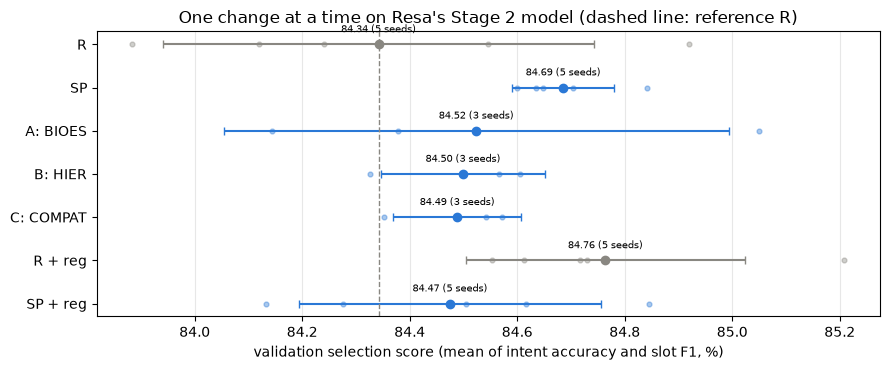

In [12]:
# One chart: every configuration's mean validation score, seeds as dots (5-seed results where available).
SHOW = {**RESULTS, **RESULTS5}
fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(SHOW)
ref = SHOW["R"]["score_mean"]
for y, k in enumerate(names):
    r = SHOW[k]
    color = "#898781" if k.startswith("R") else "#2a78d6"
    ax.errorbar(r["score_mean"], y, xerr=r["score_std"] if r["seeds"] > 1 else 0, fmt="o", color=color, capsize=3)
    ax.scatter(r["scores"], [y] * len(r["scores"]), s=12, color=color, alpha=0.4)
    ax.text(r["score_mean"], y - 0.28, f"{r['score_mean']:.2f} ({r['seeds']} seeds)", fontsize=7, ha="center")
ax.axvline(ref, color="#898781", linestyle="--", linewidth=1)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel("validation selection score (mean of intent accuracy and slot F1, %)")
ax.grid(axis="x", alpha=0.3)
ax.set_title("One change at a time on Resa's Stage 2 model (dashed line: reference R)")
fig.tight_layout()
fig.savefig(FIG_DIR / "alt_validation.png", dpi=150)
plt.show()

**Selection.** Among the finalists (5-seed results if the confirmation ran, otherwise 3 seeds), the configuration
with the highest mean validation score is selected, but only if it beats R by more than the margin; otherwise R
stays (a change that does not clearly help is not worth adding).

In [13]:
pool = RESULTS5 if RESULTS5 else RESULTS
ptable, _ = results_table(pool, {k: "R" for k in pool if k != "R"})
cands = [k for k in pool if k == "R" or ptable.loc[list(pool).index(k), "beats margin"] == "yes"]
SELECTED = max(cands, key=lambda k: pool[k]["score_mean"])
SELECTED_CFG = {**BASE_CFG, **json.loads(pool[SELECTED]["change"])}
print(f"selected: {SELECTED}  ->  changes from BASE_CFG: {json.loads(pool[SELECTED]['change']) or '(none)'}")

selected: R + reg  ->  changes from BASE_CFG: {'label_smoothing': 0.1, 'wd_alpha': 0.75}


## 8. Official training run, reload and single test evaluation

The selected configuration is trained with seed 42; the best validation checkpoint is reloaded, checked against
the log and evaluated once on test. The best single change (`best_single`) is also trained with seed 42 on
validation only, for the error comparison in Section 9.

epoch | train loss | dev loss | dev intent | dev slot F1 | dev score |   time
    1 |     3.6235 |   2.0594 |      70.59 |       44.44 |     57.51 |  56.0s *
    2 |     1.8700 |   1.5820 |      82.34 |       66.77 |     74.56 |  55.9s *
    3 |     1.5373 |   1.4515 |      84.75 |       72.39 |     78.57 |  56.0s *
    4 |     1.3779 |   1.4018 |      85.49 |       75.38 |     80.43 |  55.7s *
    5 |     1.2745 |   1.3827 |      85.39 |       77.29 |     81.34 |  56.0s *
    6 |     1.1923 |   1.3436 |      86.62 |       77.27 |     81.95 |  55.7s *
    7 |     1.1377 |   1.3711 |      86.33 |       78.69 |     82.51 |  55.8s *
    8 |     1.0840 |   1.3651 |      85.93 |       77.54 |     81.73 |  55.6s 
    9 |     1.0493 |   1.3649 |      85.88 |       78.60 |     82.24 |  55.9s 
   10 |     1.0148 |   1.3541 |      86.52 |       78.64 |     82.58 |  55.8s *
   11 |     0.9953 |   1.3521 |      86.87 |       79.80 |     83.33 |  56.0s *
   12 |     0.9666 |   1.3539 |      87.16 |

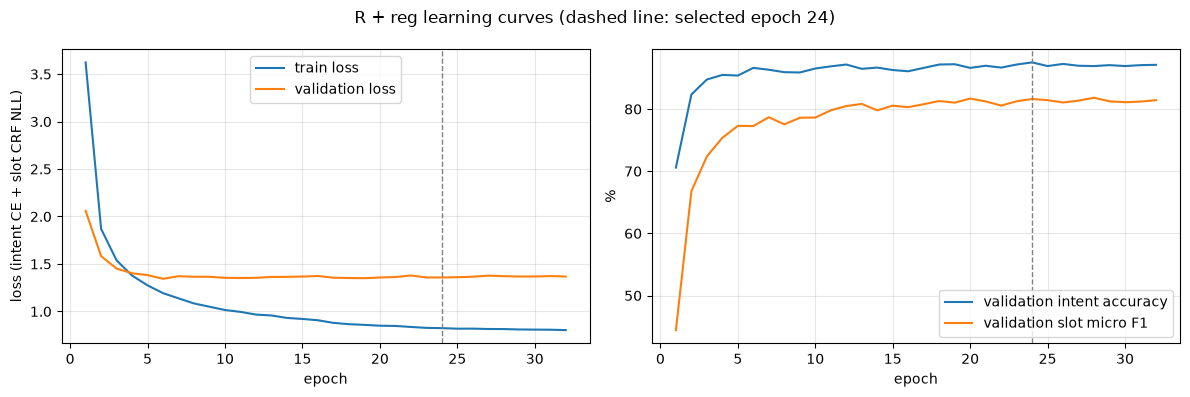

reloaded runs\alt\checkpoints\alt_selected_best.pt (epoch 24): validation score 84.5613 matches the log


,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,R + reg,Validation,"4,585,110","4,585,110",87.51,81.62,24
1,R + reg,Test,Same as above,Same as above,86.31,79.79,Same as above


In [14]:
SEL_CKPT = CKPT_DIR / "alt_selected_best.pt"
sel_model, sel_history, sel_best = run_training(SELECTED_CFG, OFFICIAL_SEED, ckpt_path=SEL_CKPT, verbose=True)
del sel_model
pd.DataFrame(sel_history).to_csv(OUT_DIR / "alt_selected_history.csv", index=False)
print(f"\nselected checkpoint: epoch {sel_best['epoch']} (of {len(sel_history)} run); validation score "
      f"{sel_best['dev_score']:.2f}; file {SEL_CKPT}; training time {sel_history[-1]['elapsed_seconds'] / 60:.1f} min")
plot_curves(sel_history, sel_best["epoch"], f"{SELECTED} learning curves", FIG_DIR / "alt_selected_curves.png")

final_model, final_ck = load_checkpoint(SEL_CKPT)
final_dev, final_dev_int, final_dev_tags = evaluate(final_model, "dev")
assert abs(final_dev["score"] - final_ck["dev_metrics"]["dev_score"]) < 1e-6, "reloaded score differs from logged best"
final_test, _, final_test_tags = evaluate(final_model, "test")
total, trainable = count_params(final_model)
print(f"reloaded {SEL_CKPT} (epoch {final_ck['epoch']}): validation score {final_dev['score']:.4f} matches the log")
display(pd.DataFrame([
    {"Model version": SELECTED, "Split": "Validation", "Total # parameters": f"{total:,}",
     "Total # trainable parameters": f"{trainable:,}", "Intent accuracy (%)": f"{final_dev['intent_acc']:.2f}",
     "Slot micro-F1 (%)": f"{final_dev['slot_f1']:.2f}", "Number of epochs": str(final_ck["epoch"])},
    {"Model version": SELECTED, "Split": "Test", "Total # parameters": "Same as above",
     "Total # trainable parameters": "Same as above", "Intent accuracy (%)": f"{final_test['intent_acc']:.2f}",
     "Slot micro-F1 (%)": f"{final_test['slot_f1']:.2f}", "Number of epochs": "Same as above"}]))
json.dump(dict(selected=SELECTED, cfg=SELECTED_CFG, epoch=final_ck["epoch"], dev=final_dev, test=final_test,
               total_params=total, best_single=best_single,
               table_3seeds=table3.to_dict("records"),
               table_5seeds=(table5.to_dict("records") if RESULTS5 else None)),
          open(OUT_DIR / "alt_final.json", "w"), indent=1, default=float)

## 9. Error comparison on validation: best single change vs R (both seed 42)

In [15]:
def model_for(name, change):
    if name == SELECTED:
        return final_model
    path = CKPT_DIR / f"alt_{re.sub(r'[^A-Za-z0-9]+', '_', name)}_seed{OFFICIAL_SEED}.pt"
    if not path.exists():
        run_training({**BASE_CFG, **change}, OFFICIAL_SEED, ckpt_path=path, verbose=False)
    return load_checkpoint(path)[0]


A_model, B_model = model_for("R", {}), model_for(best_single, best_change)
A_dev, A_int, A_tags = evaluate(A_model, "dev")
B_dev, B_int, B_tags = evaluate(B_model, "dev")
dev_ex = EXAMPLES["dev"]
gold = [ex["intent"] for ex in dev_ex]


def slot_error_kinds(pred_tags):
    kinds = Counter()
    for ex, pt in zip(dev_ex, pred_tags):
        G, P = set(tags_to_spans(ex["tags"])), set(tags_to_spans(pt))
        ov = lambda x, y: x[1] <= y[2] and y[1] <= x[2]
        for p in P - G:
            if any(g[1:] == p[1:] for g in G):
                kinds["wrong type"] += 1
            elif any(ov(g, p) and g[0] == p[0] for g in G):
                kinds["boundary"] += 1
            elif any(ov(g, p) for g in G):
                kinds["boundary + type"] += 1
            else:
                kinds["spurious"] += 1
        kinds["missed"] += sum(1 for g in G - P if not any(ov(g, p) for p in P))
    return kinds


cross = lambda ints: sum(ints[i] != gold[i] and ints[i].split("_")[0] != gold[i].split("_")[0] for i in range(len(gold)))
display(pd.DataFrame({
    "R": {"intent acc": A_dev["intent_acc"], "slot F1": A_dev["slot_f1"], "slot precision": A_dev["slot_precision"],
          "slot recall": A_dev["slot_recall"], "cross-scenario intent errors": cross(A_int), **slot_error_kinds(A_tags)},
    best_single: {"intent acc": B_dev["intent_acc"], "slot F1": B_dev["slot_f1"], "slot precision": B_dev["slot_precision"],
                  "slot recall": B_dev["slot_recall"], "cross-scenario intent errors": cross(B_int),
                  **slot_error_kinds(B_tags)},
}).round(2))
fixed = [i for i in range(len(gold)) if A_int[i] != gold[i] and B_int[i] == gold[i]]
broken = [i for i in range(len(gold)) if A_int[i] == gold[i] and B_int[i] != gold[i]]
print(f"intent: {best_single} fixes {len(fixed)} reference errors and introduces {len(broken)} new ones")
sp = lambda tags, i: spans_to_pairs(tags_to_spans(tags[i]), dev_ex[i]["tokens"], dev_ex[i]["utt"])
slot_fixed = [i for i in range(len(gold)) if sp(A_tags, i) != dev_ex[i]["gold_pairs"] and sp(B_tags, i) == dev_ex[i]["gold_pairs"]]
slot_broken = [i for i in range(len(gold)) if sp(A_tags, i) == dev_ex[i]["gold_pairs"] and sp(B_tags, i) != dev_ex[i]["gold_pairs"]]
print(f"slots (all slots of an utterance right): {best_single} fixes {len(slot_fixed)}, breaks {len(slot_broken)}")


def show(idx, n=6):
    display(pd.DataFrame([dict(utt=dev_ex[i]["utt"], gold_intent=gold[i], R_intent=A_int[i], new_intent=B_int[i],
                               gold_slots="; ".join(f"{t}: {s}" for t, s in dev_ex[i]["gold_pairs"]) or "-",
                               R_slots="; ".join(f"{t}: {s}" for t, s in sp(A_tags, i)) or "-",
                               new_slots="; ".join(f"{t}: {s}" for t, s in sp(B_tags, i)) or "-") for i in idx[:n]]))


print("intent fixed:"); show(fixed)
print("intent broken:"); show(broken)
print("slots fixed:"); show(slot_fixed)
print("slots broken:"); show(slot_broken)

,R,SP
intent acc,87.51,86.82
slot F1,81.41,81.02
slot precision,81.96,81.22
slot recall,80.86,80.82
cross-scenario intent errors,185.00,196.00
missed,154.00,157.00
boundary,116.00,106.00
spurious,131.00,155.00
wrong type,63.00,68.00
boundary + type,48.00,47.00


intent: SP fixes 35 reference errors and introduces 49 new ones
slots (all slots of an utterance right): SP fixes 63, breaks 76
intent fixed:


,utt,gold_intent,R_intent,new_intent,gold_slots,R_slots,new_slots
0,my favorite singer is shakira,music_likeness,play_music,music_likeness,artist_name: shakira,artist_name: shakira,artist_name: shakira
1,what day of the week is valentine's on,datetime_query,calendar_query,datetime_query,event_name: valentine's,event_name: valentine's,event_name: valentine's
2,show me delivery near me,takeaway_order,takeaway_query,takeaway_order,order_type: delivery,order_type: delivery,order_type: delivery
3,d. e. a. guam prescription drug abuse on the rise,news_query,qa_currency,news_query,news_topic: d. e. a. guam prescription drug ab...,-,-
4,the weather updated to the using seconds per b...,weather_query,play_music,weather_query,-,-,place_name: intellicast
5,how you know me,general_quirky,general_greet,general_quirky,-,-,-


intent broken:


,utt,gold_intent,R_intent,new_intent,gold_slots,R_slots,new_slots
0,set the volume to low,audio_volume_down,audio_volume_down,audio_volume_up,change_amount: to low,-,change_amount: to low
1,change my room lights so that i can get a good...,iot_hue_lightchange,iot_hue_lightchange,iot_hue_lightoff,color_type: good sleep,-,-
2,what things can't you do,general_quirky,general_quirky,recommendation_movies,-,-,-
3,what day of the week is thanksgiving,datetime_query,datetime_query,calendar_query,event_name: thanksgiving,event_name: thanksgiving,event_name: thanksgiving
4,please let me hear six hundred and sixty six t...,play_music,play_music,play_audiobook,song_name: six hundred and sixty six the numbe...,-,audiobook_name: six hundred and sixty six the ...
5,take me to the huffington post website,social_post,social_post,news_query,media_type: huffington post,media_type: huffington,media_type: huffington post website


slots fixed:


,utt,gold_intent,R_intent,new_intent,gold_slots,R_slots,new_slots
0,make a room darker,iot_hue_lightdim,iot_hue_lightdim,iot_hue_lightdim,house_place: room,-,house_place: room
1,set the volume to low,audio_volume_down,audio_volume_down,audio_volume_up,change_amount: to low,-,change_amount: to low
2,send me current news for the day,news_query,news_query,news_query,-,time: day,-
3,what are the lyrics to the song i will always ...,music_query,music_query,music_query,song_name: i will always love you; artist_name...,song_name: i will always love you by dolly parton,song_name: i will always love you; artist_name...
4,what will be the weather on monday this week,weather_query,weather_query,weather_query,date: monday this week,date: monday; date: this week,date: monday this week
5,i want the news about academy awards,news_query,news_query,news_query,news_topic: academy awards,media_type: academy awards,news_topic: academy awards


slots broken:


,utt,gold_intent,R_intent,new_intent,gold_slots,R_slots,new_slots
0,play me barcelona by queen,play_music,play_music,play_music,song_name: barcelona; artist_name: queen,song_name: barcelona; artist_name: queen,song_name: me barcelona; artist_name: queen
1,what day of the week is the twenty second march,datetime_query,datetime_query,datetime_query,date: twenty second march,date: twenty second march,date: the twenty second march
2,what's the weather like in new york city,weather_query,weather_query,weather_query,place_name: new york city,place_name: new york city,place_name: new york
3,tell me the hour,datetime_query,datetime_query,datetime_query,-,-,time: hour
4,please play leviathan,play_music,play_music,play_game,song_name: leviathan,song_name: leviathan,game_name: leviathan
5,your recipe of steak was superb,cooking_recipe,cooking_recipe,cooking_recipe,food_type: steak,food_type: steak,food_type: steak; food_type: superb
